# Analyses descriptives complémentaires — Compagnon Immobilier

**Périmètre :** évolution nationale des taux de crédit, ménages d'une personne par commune dans le Haut-Rhin et enregistrements BPE 2025 du Haut-Rhin.

Ce notebook présente trois analyses indépendantes de sources complémentaires. Il en expose les questions, les contrôles, les résultats et les limites, sans rapprocher ces sources entre elles ni les joindre aux annonces ou aux ventes.


## Environnement et chemins

Les chemins sont résolus à partir du dossier projet contenant les scripts et les données. Les calculs et contrôles métier restent ceux des scripts dédiés ; ce notebook les appelle et présente les graphiques avec **Matplotlib**. Exécuter avec un kernel où Matplotlib et IPython sont installés. Les sources restent séparées.

Pour éviter de construire des figures Plotly non utilisées, les scripts chargent désormais Plotly seulement dans leurs fonctions de tracé. La préparation du classement BPE est séparée de sa fonction de tracé, sans changer les calculs. Les trois versions originales sont conservées à côté des scripts avec le suffixe `.py.original`.


In [1]:
from pathlib import Path
import sys

import matplotlib
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import Markdown, display
from IPython import get_ipython

marqueur_scripts = Path("visualisations_sources_complementaires")
racines_candidates = [Path.cwd().resolve()]
shell_ipython = get_ipython()
if shell_ipython is not None:
    racines_candidates.append(Path(shell_ipython.starting_dir).resolve())
chemin_notebook_vscode = globals().get("__vsc_ipynb_file__")
if chemin_notebook_vscode:
    racines_candidates.append(Path(chemin_notebook_vscode).resolve().parent)
racines_candidates.extend(
    parent
    for racine in tuple(racines_candidates)
    for parent in racine.parents
)
RACINE_PROJET = next(
    (
        candidat.resolve()
        for candidat in racines_candidates
        if (candidat / marqueur_scripts / "graphique_01_taux_credit.py").is_file()
        and (candidat / "source de données complémentaires").is_dir()
    ),
    None,
)
if RACINE_PROJET is None:
    raise FileNotFoundError(
        "Racine du projet introuvable. Ouvrir le notebook depuis le dossier "
        "Compagnon Immobilier ou l'un de ses sous-dossiers."
    )

DOSSIER_SOURCES = RACINE_PROJET / "source de données complémentaires"
DOSSIER_SCRIPTS = RACINE_PROJET / marqueur_scripts
DOSSIER_DOC_BPE = DOSSIER_SOURCES / "documentation_BPE_2025"
if str(DOSSIER_SCRIPTS) not in sys.path:
    sys.path.insert(0, str(DOSSIER_SCRIPTS))

import graphique_01_taux_credit as taux_credit
import graphique_02_menages_seuls_par_commune as menages
import graphique_03_bpe25_types_equipements as bpe

FICHIERS_SOURCES = {
    "taux": DOSSIER_SOURCES
    / "Webstat_Export_fr_MIR1.M.FR.B.A22.A.R.A.2254U6.EUR.N (1).csv",
    "menages": DOSSIER_SOURCES / "base-ic-couples-familles-menages-2022.CSV",
    "dictionnaire_menages": DOSSIER_SOURCES
    / "meta_base-ic-couples-familles-menages-2022.CSV",
    "bpe": DOSSIER_SOURCES / "BPE25.csv",
    "table_passage_bpe": DOSSIER_DOC_BPE / "BPE25_table_passage.csv",
    "types_bpe": DOSSIER_DOC_BPE / "TYPEQU_2025.csv",
    "dictionnaire_bpe": DOSSIER_DOC_BPE / "BPE25_anonymisee_varmod.csv",
}

plt.rcParams.update(
    {
        "figure.dpi": 110,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.titleweight": "bold",
        "font.size": 10,
    }
)
print(f"Dossier projet : {RACINE_PROJET}")
print(f"Matplotlib : {matplotlib.__version__}")


Dossier projet : C:\Users\chris\OneDrive\Desktop\Projet Datasienctest
Matplotlib : 3.11.0


## 1. Évolution mensuelle des taux de crédit immobilier

**Question métier.** Comment le contexte national de financement immobilier a-t-il évolué au fil de la série disponible ?

**Source et périmètre.** Export Webstat de la Banque de France, série `MIR1.M.FR.B.A22.A.R.A.2254U6.EUR.N` : taux annuel des crédits nouveaux à l'habitat des particuliers, en pourcentage, observé en fin de mois. La série est nationale et mensuelle.

**Méthode et contrôles.** Le script dédié lit les métadonnées et les observations, convertit explicitement les décimales, contrôle les dates et valeurs, les doublons, les mois manquants et l'ordre de la série. Il calcule minimum, maximum, moyenne, médiane, variations en points de pourcentage et nombre de hausses, baisses et mois stables. Aucun mois n'est interpolé.


In [2]:
if not FICHIERS_SOURCES["taux"].is_file():
    raise FileNotFoundError(f"Source de taux absente : {FICHIERS_SOURCES['taux']}")

metadonnees_taux, lignes_taux, encodage_taux = taux_credit.lire_source(
    FICHIERS_SOURCES["taux"]
)
dates_taux, valeurs_taux, controles_taux = taux_credit.analyser_observations(
    lignes_taux
)
resultats_taux = taux_credit.calculer_resultats(dates_taux, valeurs_taux)

display(
    Markdown(
        f"""**Résultats observés**

| Indicateur | Valeur |
|---|---:|
| Période | {taux_credit.formater_date(resultats_taux['date_debut'])} – {taux_credit.formater_date(resultats_taux['date_fin'])} |
| Observations valides | {controles_taux['observations_valides']} |
| Minimum | {resultats_taux['minimum']:.2f} % ({taux_credit.formater_date(resultats_taux['date_minimum'])}) |
| Maximum | {resultats_taux['maximum']:.2f} % ({taux_credit.formater_date(resultats_taux['date_maximum'])}) |
| Moyenne / médiane | {resultats_taux['moyenne']:.2f} % / {resultats_taux['mediane']:.2f} % |
| Variation entre début et fin | {resultats_taux['variation_debut_fin']:+.2f} points |
| Hausses / baisses / mois stables | {resultats_taux['hausses_mensuelles']} / {resultats_taux['baisses_mensuelles']} / {resultats_taux['mois_sans_variation']} |

**Contrôles :** {len(controles_taux['lignes_non_exploitables'])} ligne(s) non exploitable(s), {controles_taux['mois_dupliques']} mois dupliqué(s), {len(controles_taux['mois_manquants'])} mois manquant(s), {controles_taux['dates_non_fin_de_mois']} date(s) hors fin de mois. Encodage lu : {encodage_taux}.
"""
    )
)


**Résultats observés**

| Indicateur | Valeur |
|---|---:|
| Période | 31 décembre 1998 – 31 août 2026 |
| Observations valides | 333 |
| Minimum | 1.10 % (31 décembre 2021) |
| Maximum | 6.10 % (31 octobre 2000) |
| Moyenne / médiane | 3.37 % / 3.51 % |
| Variation entre début et fin | -2.35 points |
| Hausses / baisses / mois stables | 117 / 167 / 48 |

**Contrôles :** 0 ligne(s) non exploitable(s), 0 mois dupliqué(s), 0 mois manquant(s), 0 date(s) hors fin de mois. Encodage lu : UTF-8 avec BOM.


**Visualisation.** La courbe trace les observations mensuelles présentes, sans lissage ni interpolation.


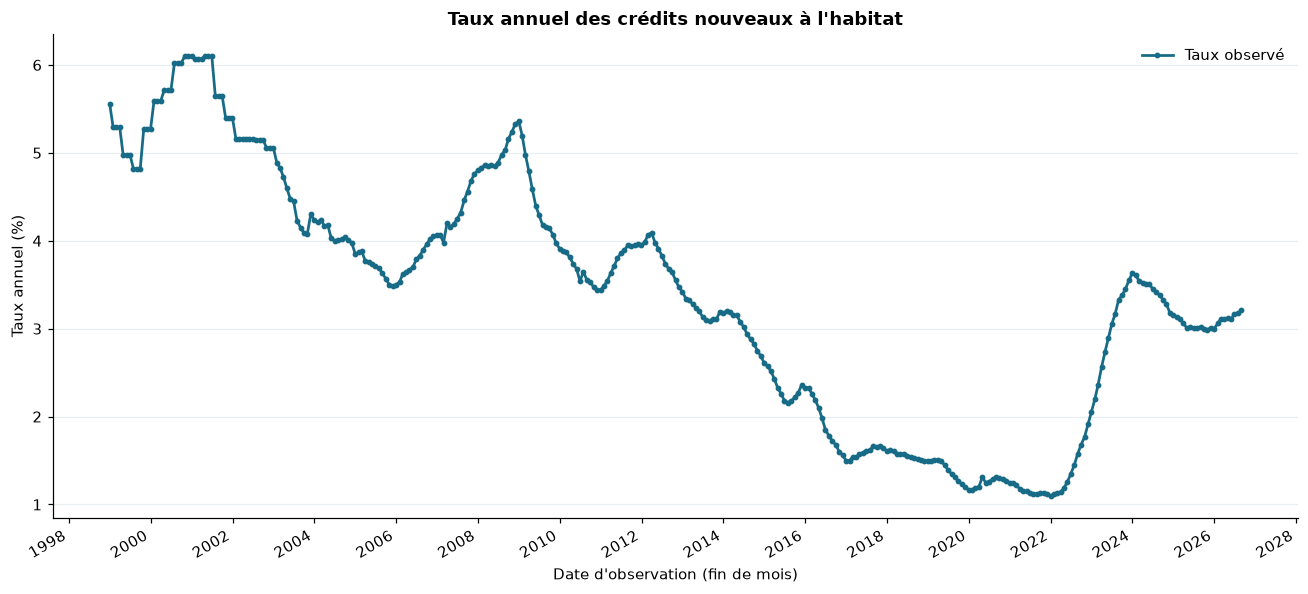

In [3]:
fig, ax = plt.subplots(figsize=(12, 5.5))
ax.plot(
    dates_taux,
    valeurs_taux,
    color="#176B87",
    linewidth=1.8,
    marker="o",
    markersize=2.8,
    label="Taux observé",
)
ax.set_title("Taux annuel des crédits nouveaux à l'habitat")
ax.set_xlabel("Date d'observation (fin de mois)")
ax.set_ylabel("Taux annuel (%)")
ax.xaxis.set_major_locator(mdates.YearLocator(2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.grid(axis="y", color="#E8EDF1")
ax.legend(frameon=False)
fig.autofmt_xdate()
fig.tight_layout()
plt.show()


**Interprétation et limites.** Les bornes, le centre de la série et le décompte des mouvements décrivent le contexte national observé ; ils ne signifient pas que le taux a évolué continûment dans un seul sens. Cette série ne mesure pas les conditions offertes à un emprunteur donné, les prix ou la demande locale. Elle ne permet pas d'établir de causalité avec les prix immobiliers.


## 2. Part des ménages d'une personne par commune du Haut-Rhin

**Question métier.** Comment varie, entre communes, la part des ménages composés d'une seule personne ?

**Source et périmètre.** Base INSEE Couples, familles et ménages 2022 et son dictionnaire. L'analyse retient les lignes communales du département 68 ; les lignes au niveau IRIS ne sont pas mélangées au périmètre communal.

**Méthode et contrôles.** L'indicateur est `C22_MENPSEUL / C22_MEN × 100`. Le script vérifie les définitions du dictionnaire, les codes géographiques et l'identification des communes (`IRIS = COM + 0000`), l'unicité, les valeurs numériques finies, les dénominateurs positifs et la cohérence des effectifs. Les statistiques et les valeurs atypiques de Tukey sont calculées selon la méthode inclusive déjà retenue dans le script.


In [4]:
for cle in ("menages", "dictionnaire_menages"):
    if not FICHIERS_SOURCES[cle].is_file():
        raise FileNotFoundError(f"Source absente ({cle}) : {FICHIERS_SOURCES[cle]}")

definitions_menages = menages.lire_dictionnaire(
    FICHIERS_SOURCES["dictionnaire_menages"]
)
if (
    definitions_menages["C22_MEN"]["LIB_VAR_LONG"] != "Nombre de ménages"
    or definitions_menages["C22_MENPSEUL"]["LIB_VAR_LONG"]
    != "Nombre de ménages d'une personne"
):
    raise ValueError("Les définitions du dictionnaire ne correspondent pas à l'indicateur attendu.")

communes_menages, controles_menages = menages.lire_et_valider_base(
    FICHIERS_SOURCES["menages"]
)
resultats_menages = menages.calculer_statistiques(communes_menages)
atypiques_menages = resultats_menages["valeurs_atypiques"]
codes_atypiques = ", ".join(
    f"{ligne['COM']} ({float(ligne['proportion_pct']):.5f} %)"
    for ligne in atypiques_menages
) or "aucune"

display(
    Markdown(
        f"""**Résultats observés**

| Indicateur | Valeur |
|---|---:|
| Communes analysées | {resultats_menages['nombre_communes']} |
| Minimum / maximum | {resultats_menages['minimum']:.5f} % / {resultats_menages['maximum']:.5f} % |
| Q1 / médiane / Q3 | {resultats_menages['q1']:.5f} % / {resultats_menages['mediane']:.5f} % / {resultats_menages['q3']:.5f} % |
| Écart interquartile | {resultats_menages['iqr']:.5f} points |
| Moyenne non pondérée des proportions communales | {resultats_menages['moyenne']:.5f} % |
| Valeurs au-delà des bornes de Tukey | {len(atypiques_menages)} : {codes_atypiques} |

**Contrôles :** {controles_menages['lignes_initiales']} lignes lues, {controles_menages['lignes_departement_68']} dans le département 68, {controles_menages['lignes_communales_departement_68']} lignes communales, {controles_menages['lignes_IRIS_exclues_du_calcul_communal']} lignes IRIS écartées ; {controles_menages['codes_commune_dupliques']} commune(s) dupliquée(s), {controles_menages['lignes_avec_valeurs_manquantes']} ligne(s) avec valeurs manquantes, {controles_menages['denominateurs_non_positifs']} dénominateur(s) non positif(s) et {controles_menages['numerateurs_incoherents']} numérateur(s) incohérent(s).
"""
    )
)


**Résultats observés**

| Indicateur | Valeur |
|---|---:|
| Communes analysées | 344 |
| Minimum / maximum | 13.19009 % / 66.66667 % |
| Q1 / médiane / Q3 | 23.06910 % / 26.39200 % / 30.32405 % |
| Écart interquartile | 7.25495 points |
| Moyenne non pondérée des proportions communales | 26.95680 % |
| Valeurs au-delà des bornes de Tukey | 3 : 68090 (41.82597 %), 68190 (66.66667 %), 68226 (41.20666 %) |

**Contrôles :** 49276 lignes lues, 495 dans le département 68, 344 lignes communales, 151 lignes IRIS écartées ; 0 commune(s) dupliquée(s), 0 ligne(s) avec valeurs manquantes, 0 dénominateur(s) non positif(s) et 0 numérateur(s) incohérent(s).


**Visualisation.** La boîte reprend explicitement les quartiles et moustaches calculés par le script ; chaque point reste une commune. Les communes atypiques selon Tukey sont colorées et leur code est annoté. Matplotlib produit une figure statique : les info-bulles par commune du graphique Plotly des scripts ne sont pas disponibles, mais les codes et proportions exacts restent accessibles dans `communes_menages`.


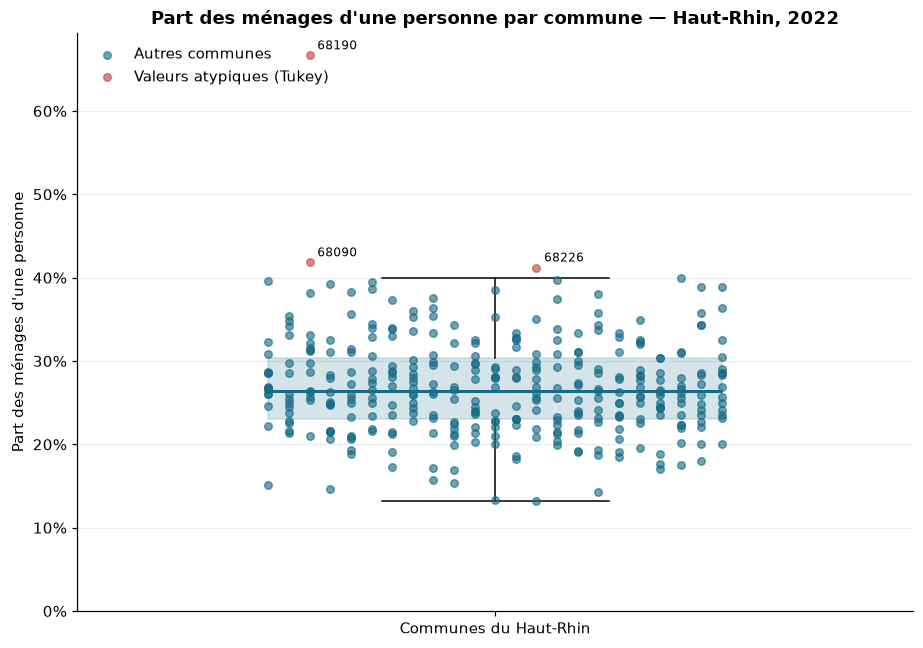

In [5]:
proportions_menages = [
    float(ligne["proportion_pct"]) for ligne in communes_menages
]
codes_atypiques_menages = {
    ligne["COM"] for ligne in atypiques_menages
}
positions_menages = [
    ((index * 37) % 23 / 22 - 0.5) * 0.38
    for index in range(len(proportions_menages))
]
est_atypique = [
    ligne["COM"] in codes_atypiques_menages
    for ligne in communes_menages
]

fig, ax = plt.subplots(figsize=(8.5, 6))
boite = ax.bxp(
    [
        {
            "label": "Communes du Haut-Rhin",
            "q1": float(resultats_menages["q1"]),
            "med": float(resultats_menages["mediane"]),
            "q3": float(resultats_menages["q3"]),
            "whislo": float(resultats_menages["moustache_basse"]),
            "whishi": float(resultats_menages["moustache_haute"]),
            "fliers": [],
        }
    ],
    positions=[0],
    widths=0.38,
    patch_artist=True,
    showfliers=False,
)
boite["boxes"][0].set(facecolor="#176B87", alpha=0.18, edgecolor="#176B87")
for mediane in boite["medians"]:
    mediane.set(color="#176B87", linewidth=2)

for indicateur, couleur, etiquette in (
    (False, "#176B87", "Autres communes"),
    (True, "#C44536", "Valeurs atypiques (Tukey)"),
):
    indices = [i for i, valeur in enumerate(est_atypique) if valeur == indicateur]
    ax.scatter(
        [positions_menages[i] for i in indices],
        [proportions_menages[i] for i in indices],
        color=couleur,
        s=24,
        alpha=0.62,
        label=etiquette,
        zorder=3,
    )
    if indicateur:
        for i in indices:
            ax.annotate(
                str(communes_menages[i]["COM"]),
                (positions_menages[i], proportions_menages[i]),
                xytext=(5, 4),
                textcoords="offset points",
                fontsize=8,
            )

ax.set_title("Part des ménages d'une personne par commune — Haut-Rhin, 2022")
ax.set_ylabel("Part des ménages d'une personne")
ax.yaxis.set_major_formatter(PercentFormatter(xmax=100, decimals=0))
ax.set_ylim(bottom=0)
ax.set_xlim(-0.35, 0.35)
ax.set_xticks([0], ["Communes du Haut-Rhin"])
ax.grid(axis="y", color="#E8EDF1")
ax.legend(frameon=False, loc="upper left")
fig.tight_layout()
plt.show()


**Interprétation et limites.** La médiane et l'intervalle interquartile décrivent la distribution entre communes ; la moyenne est une moyenne **non pondérée** des proportions communales et ne correspond pas à la proportion globale du département. L'indicateur porte sur les ménages, pas sur les personnes. Les écarts observés n'en expliquent pas les causes et le millésime 2022 ne décrit pas une évolution temporelle.


## 3. Types d'équipements enregistrés dans la BPE 2025

**Question métier.** Quels types sont les plus fréquents parmi les enregistrements de la Base permanente des équipements dans le Haut-Rhin ?

**Source et périmètre.** `BPE25.csv`, millésime 2025, filtre `DEP = '68'`, avec les trois nomenclatures officielles locales. Les effectifs portent sur les lignes BPE filtrées.

**Méthode et contrôles.** Le script dédié vérifie les nomenclatures, filtre et compte les lignes en flux, contrôle les codes observés et confronte les totaux aux contrôles de référence du script. Le classement présente les dix premiers types et un agrégat exact des autres catégories ; aucune jointure avec les deux autres sources n'est faite. Le fichier de plus de 1 Go n'est pas chargé intégralement en mémoire.


In [6]:
for cle in ("bpe", "table_passage_bpe", "types_bpe", "dictionnaire_bpe"):
    if not FICHIERS_SOURCES[cle].is_file():
        raise FileNotFoundError(f"Source BPE absente ({cle}) : {FICHIERS_SOURCES[cle]}")

passage_bpe, catalogue_bpe, definitions_bpe = bpe.lire_documentation()
effectifs_bpe, lignes_totales_bpe, lignes_68_bpe = bpe.compter_enregistrements()
codes_inconnus_bpe = effectifs_bpe.keys() - passage_bpe.keys()
if codes_inconnus_bpe:
    raise ValueError(
        "Codes TYPEQU absents de la nomenclature : "
        + ", ".join(sorted(codes_inconnus_bpe))
    )

donnees_bpe, total_autres_bpe = bpe.preparer_donnees_graphique(
    effectifs_bpe, lignes_68_bpe, passage_bpe, catalogue_bpe
)
if sum(ligne["effectif"] for ligne in donnees_bpe) != lignes_68_bpe:
    raise ValueError("Les effectifs représentés ne totalisent pas les lignes DEP=68.")

classement_bpe = donnees_bpe[1:]
tableau_classement_bpe = [
    "| Rang | Code TYPEQU | Libellé officiel | Enregistrements | Part des lignes du 68 |",
    "|---:|---|---|---:|---:|",
]
tableau_classement_bpe.extend(
    f"| {rang} | `{ligne['code']}` | {ligne['libelle']} | "
    f"{ligne['effectif']:,} | {ligne['part_pct']:.2f} % |"
    for rang, ligne in enumerate(classement_bpe, start=1)
)
display(
    Markdown(
        f"""**Contrôles :** {lignes_totales_bpe:,} lignes parcourues en flux ; {lignes_68_bpe:,} enregistrements avec `DEP = 68` ; {len(effectifs_bpe)} codes TYPEQU observés et reconnus. Somme du classement et de l'agrégat : {sum(ligne['effectif'] for ligne in donnees_bpe):,}. Le fichier BPE reste lu ligne par ligne.

**Dix premiers types**

{chr(10).join(tableau_classement_bpe)}

**Autres types :** {total_autres_bpe:,} enregistrements regroupant {len(effectifs_bpe) - len(classement_bpe)} codes.
"""
    )
)


**Contrôles :** 2,921,770 lignes parcourues en flux ; 27,940 enregistrements avec `DEP = 68` ; 224 codes TYPEQU observés et reconnus. Somme du classement et de l'agrégat : 27,940. Le fichier BPE reste lu ligne par ligne.

**Dix premiers types**

| Rang | Code TYPEQU | Libellé officiel | Enregistrements | Part des lignes du 68 |
|---:|---|---|---:|---:|
| 1 | `A504` | RESTAURANT- RESTAURATION RAPIDE | 2,400 | 8.59 % |
| 2 | `A501` | COIFFURE | 1,198 | 4.29 % |
| 3 | `A301` | RÉPARATION AUTOMOBILE ET DE MATÉRIEL AGRICOLE | 1,191 | 4.26 % |
| 4 | `A507` | INSTITUT DE BEAUTÉ-ONGLERIE | 1,093 | 3.91 % |
| 5 | `A402` | PLÂTRIER PEINTRE | 1,083 | 3.88 % |
| 6 | `A404` | PLOMBIER COUVREUR CHAUFFAGISTE | 1,015 | 3.63 % |
| 7 | `D281` | INFIRMIER | 940 | 3.36 % |
| 8 | `A403` | MENUISIER CHARPENTIER SERRURIER | 912 | 3.26 % |
| 9 | `A401` | MAÇON | 879 | 3.15 % |
| 10 | `A405` | ÉLECTRICIEN | 803 | 2.87 % |

**Autres types :** 16,426 enregistrements regroupant 214 codes.


**Visualisation.** Les barres montrent les dix types classés et l'agrégat « Autres types ». Le tableau ci-dessus conserve les codes officiels et les parts de chaque type affiché ; l'agrégat n'est pas une catégorie BPE réelle.


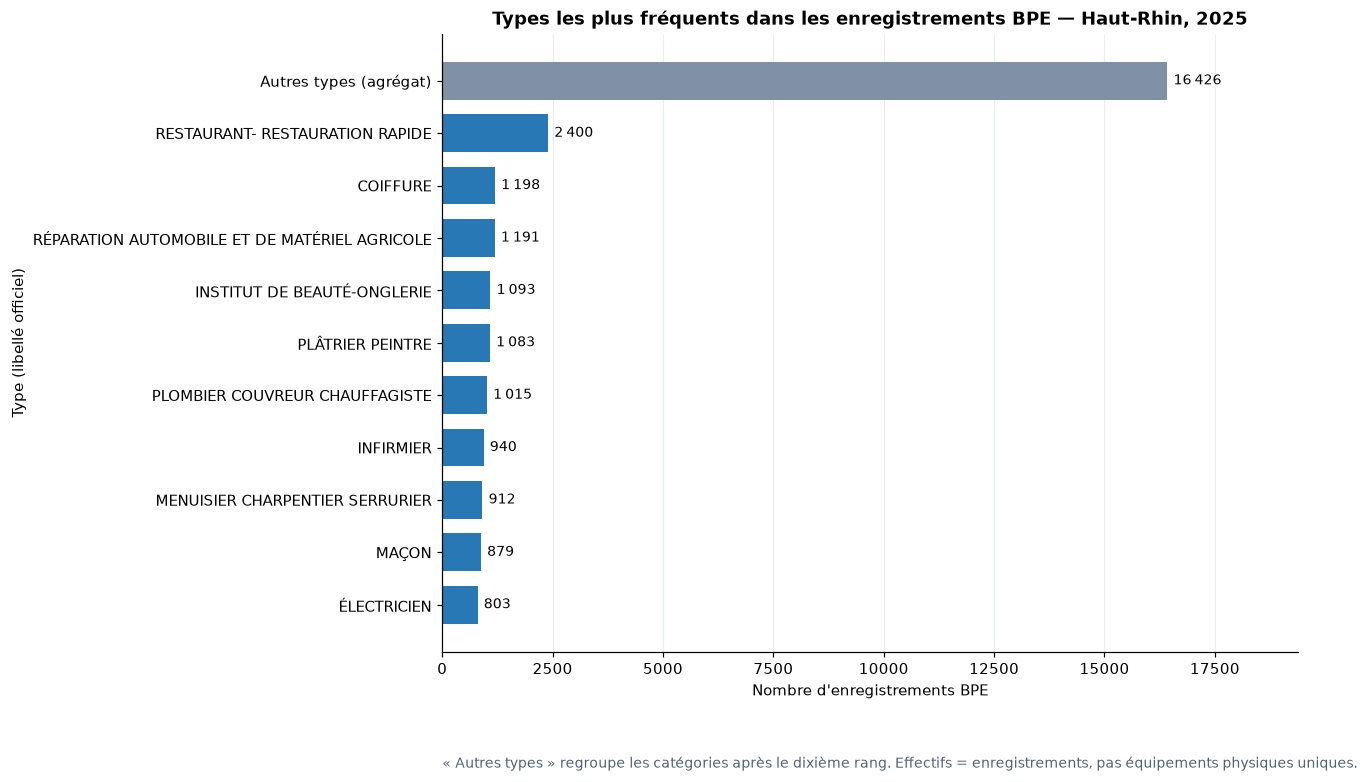

In [7]:
libelles_bpe = [ligne["categorie"] for ligne in donnees_bpe]
valeurs_bpe = [int(ligne["effectif"]) for ligne in donnees_bpe]
couleurs_bpe = [
    "#8091A5" if ligne["code"] == "—" else "#2878B5"
    for ligne in donnees_bpe
]

fig, ax = plt.subplots(figsize=(12, 7.2))
barres = ax.barh(libelles_bpe, valeurs_bpe, color=couleurs_bpe, height=0.72)
ax.invert_yaxis()
ax.set_title("Types les plus fréquents dans les enregistrements BPE — Haut-Rhin, 2025")
ax.set_xlabel("Nombre d'enregistrements BPE")
ax.set_ylabel("Type (libellé officiel)")
ax.set_xlim(0, max(valeurs_bpe) * 1.18)
ax.grid(axis="x", color="#E8EDF1")
ax.set_axisbelow(True)
ax.bar_label(
    barres,
    labels=[f"{valeur:,}".replace(",", "\u202f") for valeur in valeurs_bpe],
    padding=4,
    fontsize=9,
)
ax.text(
    0,
    -0.17,
    "« Autres types » regroupe les catégories après le dixième rang. "
    "Effectifs = enregistrements, pas équipements physiques uniques.",
    transform=ax.transAxes,
    ha="left",
    va="top",
    fontsize=9,
    color="#526273",
)
fig.tight_layout()
plt.show()


**Interprétation et limites.** Le classement décrit la composition des enregistrements BPE du périmètre, et non l'accessibilité, la qualité ou l'adéquation des services aux besoins locaux. Une ligne n'est pas nécessairement un équipement physique unique ; aucune déduplication n'est appliquée. « Autres types » masque le détail des catégories après le dixième rang, et l'absence d'une modalité dans les lignes ne prouve pas l'absence réelle du service.


## Synthèse générale

Les trois analyses apportent des repères descriptifs distincts : contexte national du crédit, dispersion communale d'un indicateur de ménages en 2022 et composition des enregistrements BPE 2025 dans le Haut-Rhin. Les unités, les territoires et les périodes diffèrent ; ces sources ne sont ni jointes ni interprétées comme des explications causales du marché immobilier.

Les résultats ne peuvent être présentés comme validés qu'après exécution du notebook dans un environnement contenant Matplotlib et les dépendances des scripts, puis comparaison des sorties avec les comptes rendus de référence.
